# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [2]:
cell_img = plt.imread('data/cells.png')
cell_img.resize(256,256)
plt.figure()
plt.imshow(cell_img)
plt.colorbar()

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


complex128


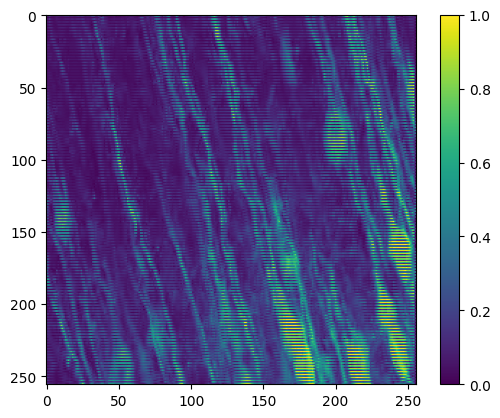

In [3]:
cell_ft = np.fft.fft2(cell_img)
print(cell_ft.dtype)

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [4]:
amplitude_cells_ns = np.abs(cell_ft)
phase_cells_ns = np.angle(cell_ft)

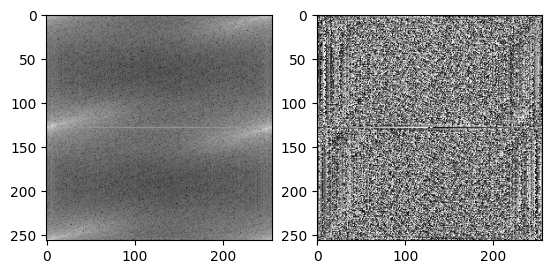

In [5]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_cells_ns), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_cells_ns, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


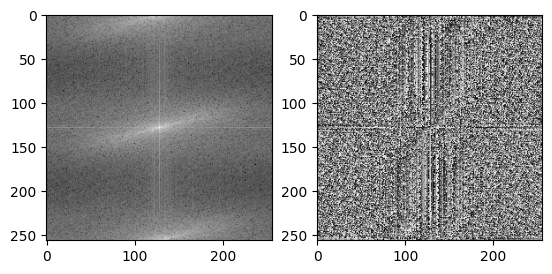

In [6]:
cell_shifted = np.fft.fftshift(cell_ft)
amplitude = np.abs(cell_shifted)
phase = np.angle(cell_shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


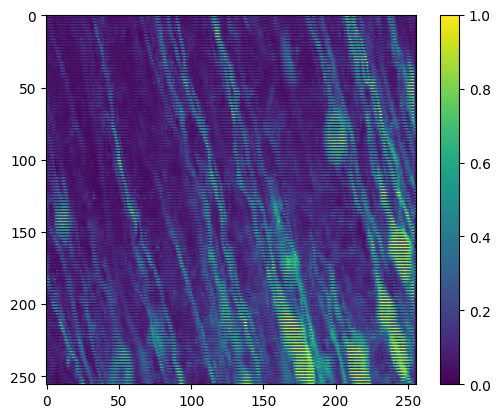

In [7]:
cell_IFFT = np.fft.ifft2(cell_ft)
plt.figure()
plt.imshow(cell_IFFT.real)
plt.colorbar()

---


**[Task 2 (a).]()** Load the brain MR image.


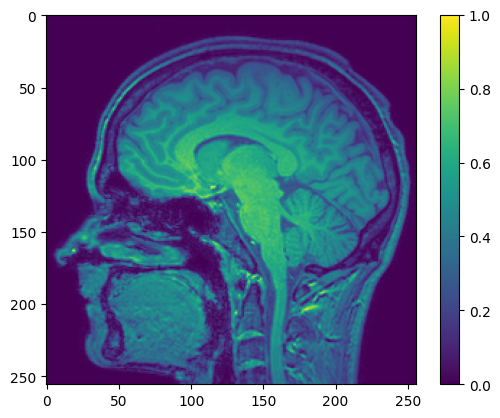

In [8]:
brain = plt.imread('data/brain_mri.png')

plt.figure()
plt.imshow(brain)
plt.colorbar()

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


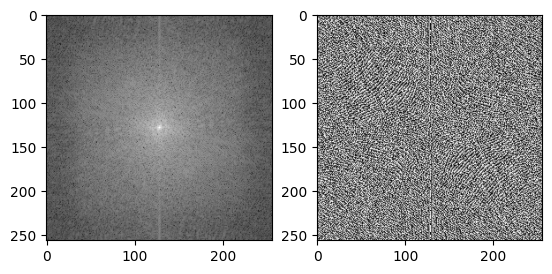

In [9]:
brain_ft = np.fft.fft2(brain)
amplitude_brain_ns = np.abs(brain_ft)
phase_brain_ns = np.angle(brain_ft)

brain_shifted = np.fft.fftshift(brain_ft)

amplitude_brain = np.abs(brain_shifted)
phase_brain = np.angle(brain_shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_brain), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_brain, 'gray')


In [10]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


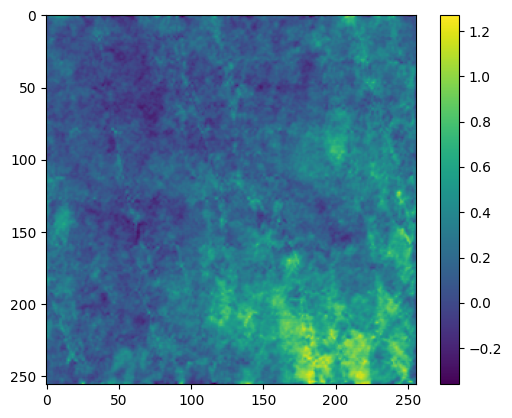

In [11]:
merged = to_complex_array(amplitude_brain_ns, phase_cells_ns)
merged_IFFT = np.fft.ifft2(merged)
plt.figure()
plt.imshow(merged_IFFT.real)
plt.colorbar()


**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


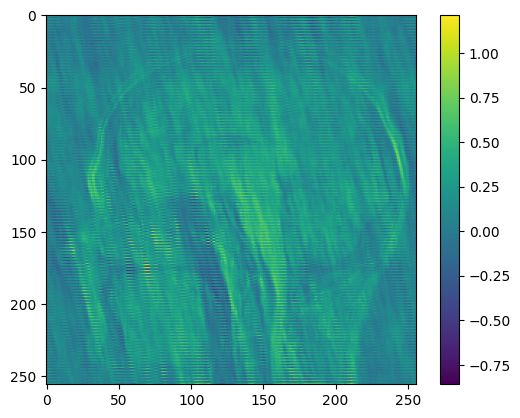

In [12]:
merged = to_complex_array(amplitude_cells_ns, phase_brain_ns)
merged_IFFT = np.fft.ifft2(merged)
plt.figure()
plt.imshow(merged_IFFT.real)
plt.colorbar()

---


**[Task 3 (a).]()** Create a lowpass filter mask.


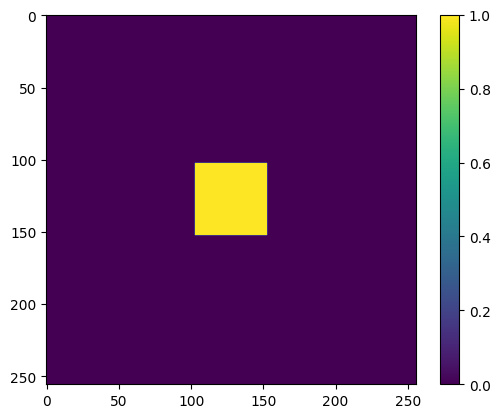

In [13]:
filter_window_size = 50
window = filter_window_size // 2

filtermask_lowpass = np.zeros(cell_img.shape) #quadratisch
mid = len(filtermask_lowpass)//2
filtermask_lowpass[(mid-window):(mid+window), (mid-window):(mid+window)] = 1
plt.figure()
plt.imshow(filtermask_lowpass)
plt.colorbar()


**[Task 3 (b).]()** Create a highpass filter maks.


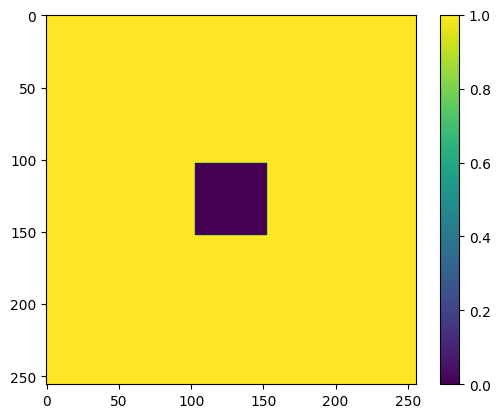

In [14]:
filtermask_highpass = 1- filtermask_lowpass
plt.figure()
plt.imshow(filtermask_highpass)
plt.colorbar()

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


#No Filer:
highpass filter
lowpass filter


/tmp/ipykernel_1262/1498737261.py:18: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(ampl_filter_h), 'gray')
/tmp/ipykernel_1262/1498737261.py:26: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(ampl_filter_l), 'gray')


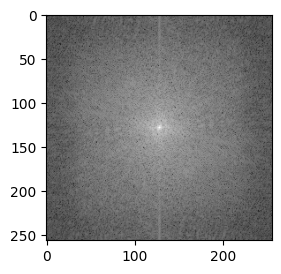

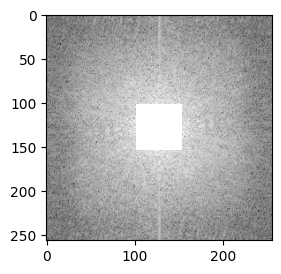

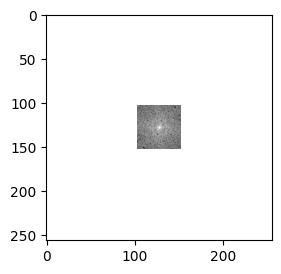

In [15]:
brain_ft = np.fft.fft2(brain)
brain_shifted = np.fft.fftshift(brain_ft)

amplitude_brain = np.abs(brain_shifted)
phase_brain = np.angle(brain_shifted)

print("#No Filer:")
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_brain), 'gray')


print("highpass filter")
ampl_filter_h = amplitude_brain*filtermask_highpass

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(ampl_filter_h), 'gray')


print("lowpass filter")
ampl_filter_l = amplitude_brain*filtermask_lowpass

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(ampl_filter_l), 'gray')



**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


merged highpass
merged lowpass


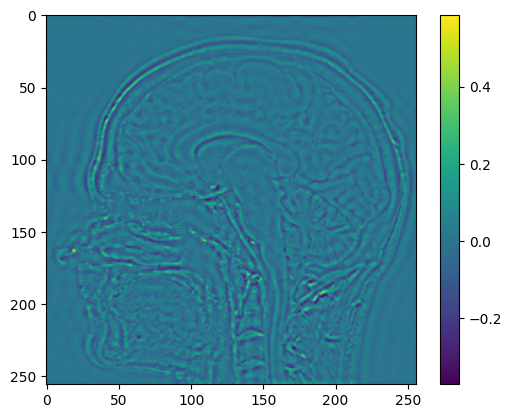

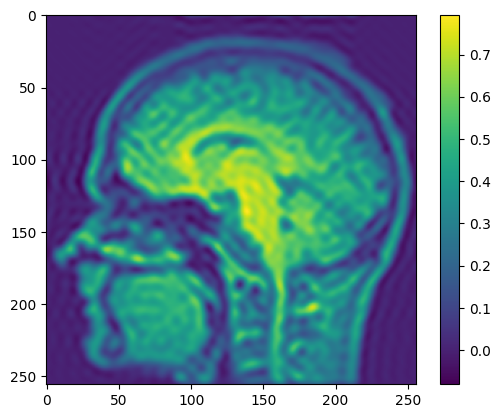

In [16]:

# merge the filtered images
print("merged highpass")
merged = to_complex_array(ampl_filter_h, phase_brain)
merged_IFFT = np.fft.ifftshift(merged)
merged_IFFT = np.fft.ifft2(merged_IFFT)
plt.figure()
plt.imshow(merged_IFFT.real)
plt.colorbar()

print("merged lowpass")
merged = to_complex_array(ampl_filter_l, phase_brain)
merged_IFFT = np.fft.ifftshift(merged)
merged_IFFT = np.fft.ifft2(merged_IFFT)
plt.figure()
plt.imshow(merged_IFFT.real)
plt.colorbar()



---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [17]:
def dft(img):
    result = np.zeros(img.shape, dtype = complex)
    M, N = img.shape

    for u in range (M):
        for v in range (N):
            for x in range (M):
                for y in range (N):
                    result[u, v] += img[x, y]*np.exp(-2j*np.pi*(u*x/M+v*y/N))
    return result/(M*N)



**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [57]:
def IDFT(img):
    M,N = img.shape
    result = np.zeros(img.shape, dtype = complex)
    for u in range (M):
            for v in range (N):
                for x in range (M):
                    for y in range (N):
                        result[u, v] += img[x, y]*np.exp(2j*np.pi*(u*x/M+v*y/N))
    return result
    

Due to high computational costs, we need to resize the image.


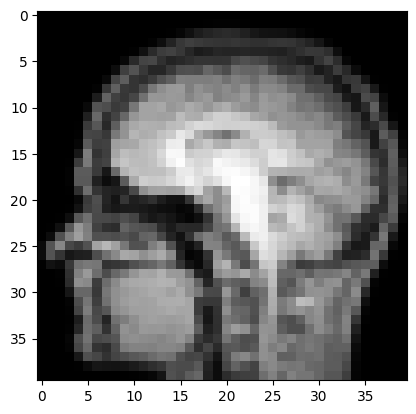

In [34]:
test_img = resize(brain, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


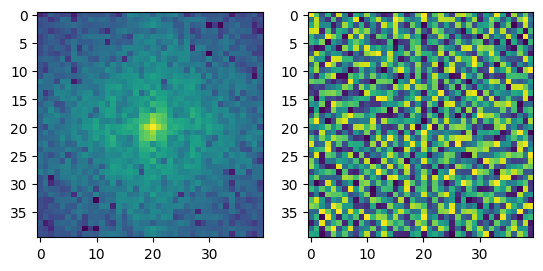

In [50]:
brain_test = dft(test_img)

brain_shift = np.fft.fftshift(brain_test)
amplitude_brain = np.abs(brain_shift)
phase_brain = np.angle(brain_shift)
plt.figure()
plt.subplot(1,2,1)
plt.imshow(np.log(amplitude_brain))
plt.subplot(1,2,2)
plt.imshow(phase_brain)


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


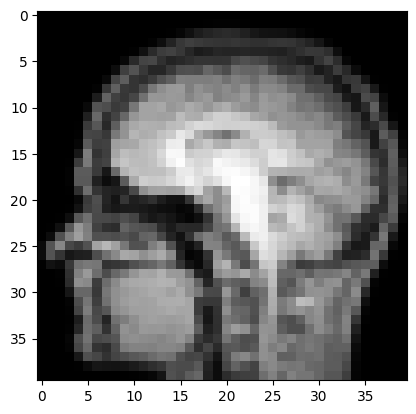

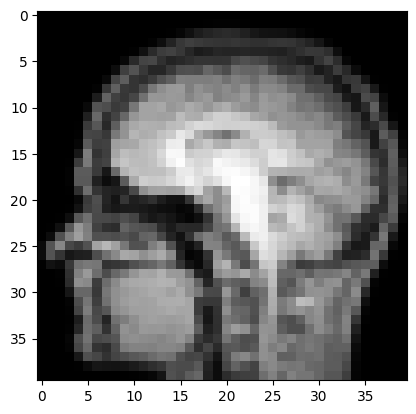

In [59]:
braini = np.fft.ifftshift(brain_shift)
brainio = IDFT(braini)

plt.figure()
plt.imshow(brainio.real, "gray")
plt.figure()
plt.imshow(np.abs(brainio), "gray")

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
